# Exercice 12 : Cinq graphiques, cinq réponses

In [7]:
import ssl
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns

ssl._create_default_https_context = ssl._create_unverified_context
sns.set_theme(style="whitegrid")
BLEU = "#2a78d6"
ORANGE = "#eb6834"
Path("figures").mkdir(exist_ok=True)

titanic = pd.read_csv("../exercice-08/data/titanic_propre.csv")
titanic_brut = sns.load_dataset("titanic")
taxis = sns.load_dataset("taxis")
taxis["pickup"] = pd.to_datetime(taxis["pickup"])

## 1. Quel âge avaient les passagers ?

**Type :** histogramme, car l'âge est une seule variable quantitative dont on veut voir la distribution.

On utilise les âges d'origine : dans le fichier nettoyé, les 177 âges imputés par la médiane créent un faux pic (117 passagers à 25 ans).

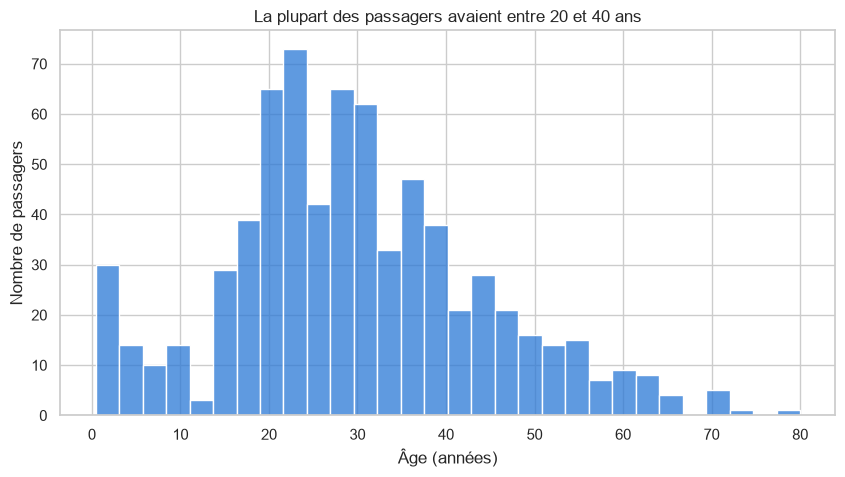

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=titanic_brut, x="age", bins=30, color=BLEU, ax=ax)
ax.set_title("La plupart des passagers avaient entre 20 et 40 ans")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("Nombre de passagers")
fig.savefig("figures/01_ages.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion :** la population est jeune : la majorité des passagers dont l'âge est connu avaient entre 20 et 40 ans. On remarque aussi un petit groupe d'enfants de moins de 10 ans, et très peu de passagers au-delà de 60 ans.

## 2. La survie selon la classe et le sexe

**Type :** barres groupées, car on compare une mesure (le taux de survie) entre deux catégories croisées ; le sexe est ajouté par la couleur (`hue`).

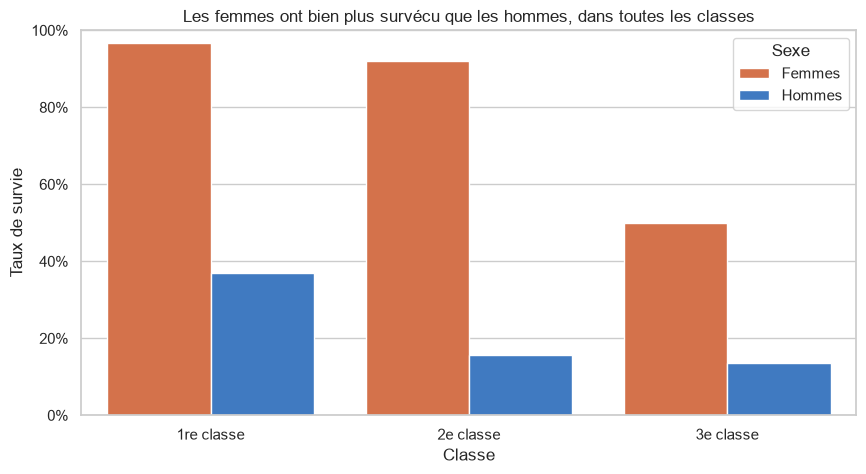

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=titanic, x="class", y="survived", hue="sex",
    order=["First", "Second", "Third"], hue_order=["female", "male"],
    palette=[ORANGE, BLEU], errorbar=None, ax=ax,
)
ax.set_title("Les femmes ont bien plus survécu que les hommes, dans toutes les classes")
ax.set_xlabel("Classe")
ax.set_ylabel("Taux de survie")
ax.set_xticks([0, 1, 2], ["1re classe", "2e classe", "3e classe"])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Femmes", "Hommes"], title="Sexe")
fig.savefig("figures/02_survie_classe_sexe.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion :** dans chaque classe, les femmes ont survécu bien plus que les hommes (97 % contre 37 % en 1re classe). La classe compte aussi : les femmes de 3e classe n'ont survécu qu'à 50 %, contre plus de 90 % en 1re et 2e.

## 3. Le prix du billet selon la classe

**Type :** boîtes à moustaches, car on compare la distribution d'une mesure (le prix) entre plusieurs catégories, valeurs extrêmes comprises.

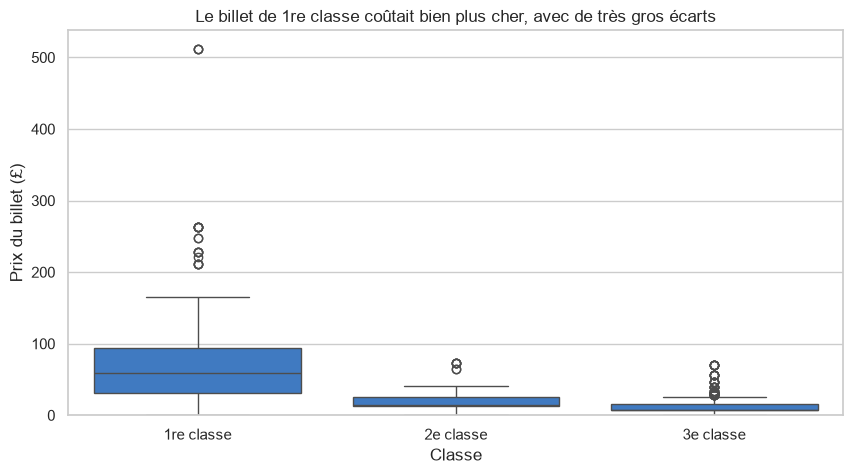

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=titanic, x="class", y="fare",
    order=["First", "Second", "Third"], color=BLEU, ax=ax,
)
ax.set_title("Le billet de 1re classe coûtait bien plus cher, avec de très gros écarts")
ax.set_xlabel("Classe")
ax.set_ylabel("Prix du billet (£)")
ax.set_xticks([0, 1, 2], ["1re classe", "2e classe", "3e classe"])
ax.set_ylim(bottom=0)
fig.savefig("figures/03_prix_classe.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion :** le prix médian d'un billet de 1re classe (59 £) est environ 4 fois celui de la 2e (14 £) et 7 fois celui de la 3e (8 £). La 1re classe est aussi très dispersée : certains billets dépassent 500 £, alors que les 2e et 3e restent sous 75 £.

## 4. Taxis : le chiffre d'affaires jour après jour

**Type :** courbe, car on suit l'évolution d'une mesure dans le temps. On ajoute la moyenne glissante sur 7 jours pour lisser les variations de la semaine.

On garde uniquement le mois de mars : le 28 février ne compte qu'une course et ferait croire à une chute.

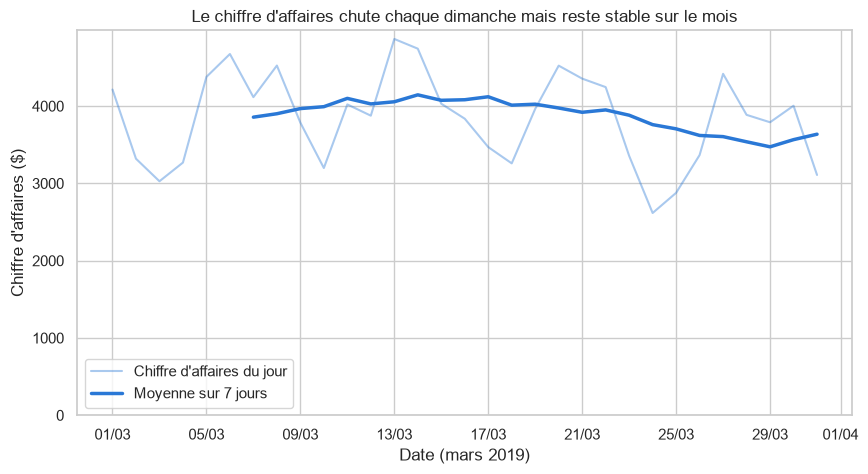

In [11]:
taxis_mars = taxis[taxis["pickup"] >= "2019-03-01"]
ca_par_jour = taxis_mars.set_index("pickup").resample("D")["total"].sum()
ca_moyenne_7j = ca_par_jour.rolling(7).mean()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=ca_par_jour.index, y=ca_par_jour.values, color=BLEU, alpha=0.4,
             label="Chiffre d'affaires du jour", ax=ax)
sns.lineplot(x=ca_moyenne_7j.index, y=ca_moyenne_7j.values, color=BLEU, linewidth=2.5,
             label="Moyenne sur 7 jours", ax=ax)
ax.set_title("Le chiffre d'affaires chute chaque dimanche mais reste stable sur le mois")
ax.set_xlabel("Date (mars 2019)")
ax.set_ylabel("Chiffre d'affaires ($)")
ax.set_ylim(bottom=0)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
fig.savefig("figures/04_ca_par_jour.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion :** le chiffre d'affaires quotidien varie de 2 600 $ (dimanche 24 mars) à 4 900 $ (mercredi 13 mars). Les creux tombent chaque dimanche. La moyenne sur 7 jours reste entre 3 500 et 4 100 $, avec une légère baisse sur la dernière semaine.

## 5. Taxis : le lien entre distance et prix

**Type :** nuage de points, car on cherche le lien entre deux mesures quantitatives.

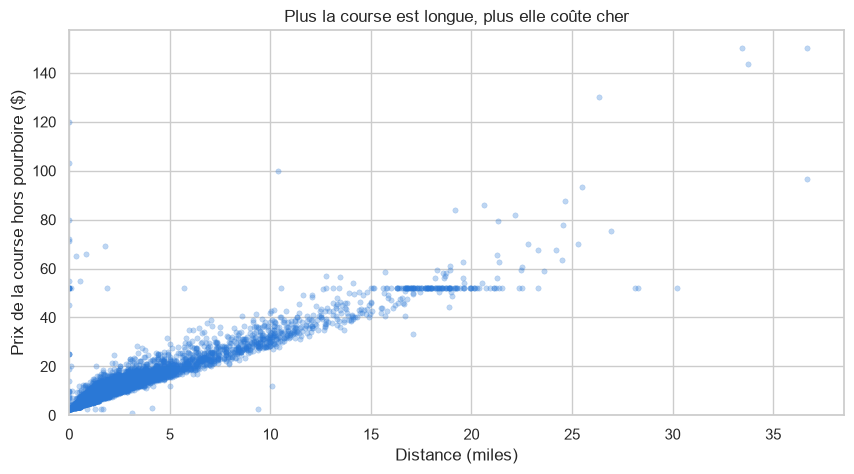

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=taxis, x="distance", y="fare", color=BLEU, alpha=0.3, s=15,
                edgecolor=None, ax=ax)
ax.set_title("Plus la course est longue, plus elle coûte cher")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Prix de la course hors pourboire ($)")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
fig.savefig("figures/05_distance_prix.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion :** le prix augmente presque proportionnellement à la distance (corrélation de 0,92), car le tarif dépend des miles parcourus. La ligne horizontale à 52 $ entre 15 et 30 miles correspond au forfait de l'aéroport JFK : 114 des 131 courses à ce prix partent de JFK ou y arrivent.